# 05 - Task 4: the Oberdorfer N999R pump, datasheet versus tests, and a pump model

**Brief:** *contextualisation of pump test data against the OEM (Oberdorfer N999R) datasheet and
construction of a pump surface map / pump model.* The Pump Datasets Specification adds three
questions, answered in sections 2-4:

* quantify where each test stopped (the valve end point) and comment on it;
* explain why flow collapses above 600 rpm in the initial campaign but not in the final one;
* build the model from the final (latest) campaign.

Data: 16 tests from the initial campaign (2021-07-28, 400-1140 rpm) and 6 from the final campaign
(2023-02-02, 700-950 rpm). In each test the pump runs at a fixed speed while the two main-line valves
close together, loading the pump from minimum to high pressure. Logged every 200 ms.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fueltwin import config, features, hydraulics as hy, plotting as pl, pump, pumpmodel as pm

pl.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
pt = pump.load_all()
ini, fin = pt[pt["campaign"] == "initial"], pt[pt["campaign"] == "final"]
RELIEF = config.RELIEF_VALVE_SETTING_BAR

## 1. What the datasheet says

The N999 datasheet gives one performance chart (water, 70 F) with straight flow-pressure lines at
1140 and 1750 rpm, plus shaft power. Read off the chart and converted to SI:

In [2]:
oem = pm.oem_si_table()
oem

,rpm,Q_at_0bar_Lpm,slope_Lpm_per_bar,displacement_mL_rev,shutoff_dP_bar
0,1140,2.404,-0.251,2.109,9.584
1,1750,3.823,-0.227,2.185,16.848


* A positive-displacement pump: flow at zero pressure is set by speed (about **2.1-2.2 mL per
  revolution**), and it falls in a straight line as pressure rises because more fluid slips back
  through the gear clearances (about **0.23-0.25 L/min per bar**).
* The "R" in N999R means a **built-in relief valve**, factory-set to **50 psig = 3.45 bar**
  (specification sheet, p. 3). Above that pump pressure it opens and returns flow to the suction side.
  The datasheet stresses it is a safety device for intermittent use, not a flow control.
* The chart is for the pump without the relief valve, and for water, which is also the test fluid
  here (the logged density, 997.5 kg/m3, is water at about 24 C).

## 2. The tests, and where each one stopped

In [3]:
tests = pump.test_summary(pt)
onset = pd.DataFrame([{"test": t, **pm.relief_onset(g)} for t, g in pt.groupby("test")])
tests = tests.merge(onset[["test", "onset_dP_bar", "flow_shortfall_at_end_Lpm"]], on="test")
tests["exceeds relief setting"] = tests["dP_max"] > RELIEF
tests.to_csv(config.TABLE_DIR / "05_pump_tests.csv", index=False)
tests[["test", "duration_s", "valve_end_pct", "dP_start", "dP_max", "exceeds relief setting", "onset_dP_bar",
       "Q_start", "Q_end", "flow_shortfall_at_end_Lpm"]]

,test,duration_s,valve_end_pct,dP_start,dP_max,exceeds relief setting,onset_dP_bar,Q_start,Q_end,flow_shortfall_at_end_Lpm
0,final-700,171.8,24.9,1.177,3.184,False,NaN,1.228,0.813,8.121e-03
1,final-750,209.2,34.9,1.313,2.808,False,NaN,1.302,1.006,4.234e-03
2,final-800,143.4,34.9,1.473,2.949,False,NaN,1.374,1.095,4.956e-04
3,final-850,148.0,34.9,1.631,3.116,False,NaN,1.450,1.175,3.755e-03
4,final-900,163.8,34.9,1.800,3.261,False,NaN,1.531,1.240,2.690e-02
5,final-950,147.8,34.9,1.951,3.367,False,NaN,1.601,1.297,4.388e-02
6,initial-400,239.8,9.9,0.447,2.612,False,NaN,0.700,0.166,-5.336e-02
7,initial-450,239.8,9.9,0.540,3.303,False,NaN,0.784,0.124,-7.575e-02
8,initial-500,239.8,9.9,0.652,3.434,False,NaN,0.872,0.206,-5.979e-02
9,initial-550,239.8,9.9,0.764,3.542,True,NaN,0.956,0.290,-3.834e-02


**Valve end points (answering the specification's question).** Both valves always move together.
In the **initial campaign every test runs to the same end point, 9.9 % open** (command 5 584),
whatever the speed, so the higher the speed the higher the pump pressure at the end: 2.6 bar at
400 rpm rising to 3.86 bar at 1140 rpm. From 550 rpm upwards every test passes the 3.45 bar relief
setting.

In the **final campaign the end point was chosen per test**: 25 % open at 700 rpm and 35 % open at
750-950 rpm. Those end points keep the maximum pump pressure between 2.8 and 3.37 bar, **below the relief
setting in every test**. The 700 rpm test could close further (to 25 %) because at that speed the
same valve opening produces less pressure. The final campaign was therefore designed to map only the
pump's own characteristic, and stops just short of where the relief valve would contaminate it.

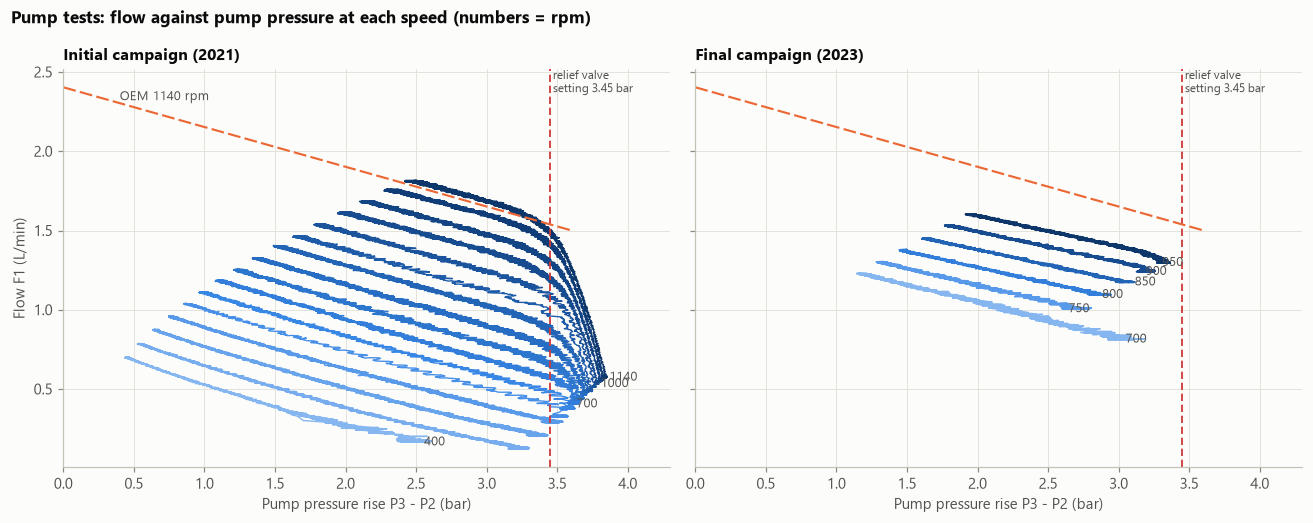

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, (camp, df) in zip(axes, [("initial", ini), ("final", fin)]):
    speeds = sorted(df["nominal_rpm"].unique())
    cmap = pl.BLUE_RAMP
    for i, rpm in enumerate(speeds):
        g = df[df["nominal_rpm"] == rpm]
        col = cmap(0.25 + 0.75 * i / max(1, len(speeds) - 1))
        ax.plot(g["dP_pump"], g["Q"], lw=0.9, color=col)
        if camp == "final" or rpm in (400, 700, 1000, 1140):
            pl.label_end(ax, g["dP_pump"].iloc[-1], g["Q"].iloc[-1], f"{rpm}", dx=3)
    ax.axvline(RELIEF, color=pl.STATUS["critical"], lw=1.2, ls=(0, (4, 2)))
    ax.text(RELIEF, 1.0, " relief valve\n setting 3.45 bar", transform=ax.get_xaxis_transform(), va="top",
            fontsize=8, color=pl.INK_2)
    dp = np.linspace(0, 3.6, 50)
    ax.plot(dp, pm.oem_flow(1140, dp), color=pl.SERIES[1], lw=1.4, ls=(0, (6, 2)))
    if camp == "initial":
        pl.label_end(ax, 0.4, pm.oem_flow(1140, 0.4), "OEM 1140 rpm", dx=0, va="bottom")
    ax.set_title(f"{camp.capitalize()} campaign ({'2021' if camp == 'initial' else '2023'})")
    ax.set_xlabel("Pump pressure rise P3 - P2 (bar)")
    ax.set_xlim(0, 4.3)
axes[0].set_ylabel("Flow F1 (L/min)")
fig.suptitle("Pump tests: flow against pump pressure at each speed (numbers = rpm)", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
fig.tight_layout()
pl.save(fig, "05_pump_curves")
plt.show()

## 3. Why the initial campaign's flow collapses above 600 rpm

Each curve is straight until the pump pressure reaches about 3.3-3.6 bar, then bends sharply down.
That pressure is the **relief valve setting**. Once it cracks open, extra closing of the main-line
valves no longer raises the pump pressure much (it is capped near 3.6-3.9 bar); instead, more and
more of the pump's flow is returned through the relief valve and never reaches the flow meter.

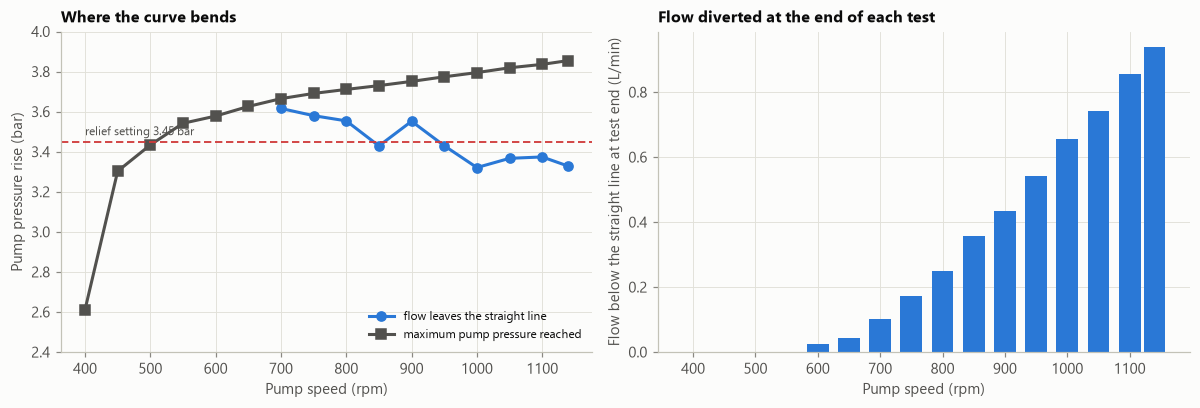

In [5]:
o = tests[tests["campaign"] == "initial"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(o["nominal_rpm"], o["onset_dP_bar"], marker="o", color=pl.SERIES[0], label="flow leaves the straight line")
ax.plot(o["nominal_rpm"], o["dP_max"], marker="s", color=pl.INK_2, label="maximum pump pressure reached")
ax.axhline(RELIEF, color=pl.STATUS["critical"], lw=1.2, ls=(0, (4, 2)))
ax.text(400, RELIEF + 0.02, "relief setting 3.45 bar", fontsize=8, color=pl.INK_2, va="bottom")
ax.set_xlabel("Pump speed (rpm)")
ax.set_ylabel("Pump pressure rise (bar)")
ax.set_ylim(2.4, 4.0)
ax.legend(fontsize=8, loc="lower right")
ax.set_title("Where the curve bends")
ax = axes[1]
ax.bar(o["nominal_rpm"], o["flow_shortfall_at_end_Lpm"].clip(lower=0), width=35, color=pl.SERIES[0])
ax.set_xlabel("Pump speed (rpm)")
ax.set_ylabel("Flow below the straight line at test end (L/min)")
ax.set_title("Flow diverted at the end of each test")
fig.tight_layout()
pl.save(fig, "05_relief_valve")
plt.show()

* From **700 rpm** upwards the bend is detected at **3.3-3.6 bar**, bracketing the 3.45 bar setting
  (a spring relief valve "cracks" gradually). Below 650 rpm the pressure barely reaches the setting,
  so no clear bend appears.
* The flow lost at the end of the test **grows with speed**, from about 0.1 L/min at 700 rpm to
  0.9 L/min at 1140 rpm, exactly the brief's "the higher the pump speed, the higher the drop". With the
  pressure capped by the relief valve, a faster pump has more surplus flow to recirculate.
* Bardakis (2019) found the same knee at about 3.4 bar on this testbed and attributed it to the
  built-in relief valve. **The final campaign avoids it by stopping the valves earlier**, so its data
  describes the pump alone, which is why the brief asks for the model to be built from it.

## 4. The pump against its datasheet

Straight lines fitted to the part of every test below 3.0 bar (well clear of the relief valve) give
each test's zero-pressure flow and slip slope. Dividing the intercept by speed gives the displacement.

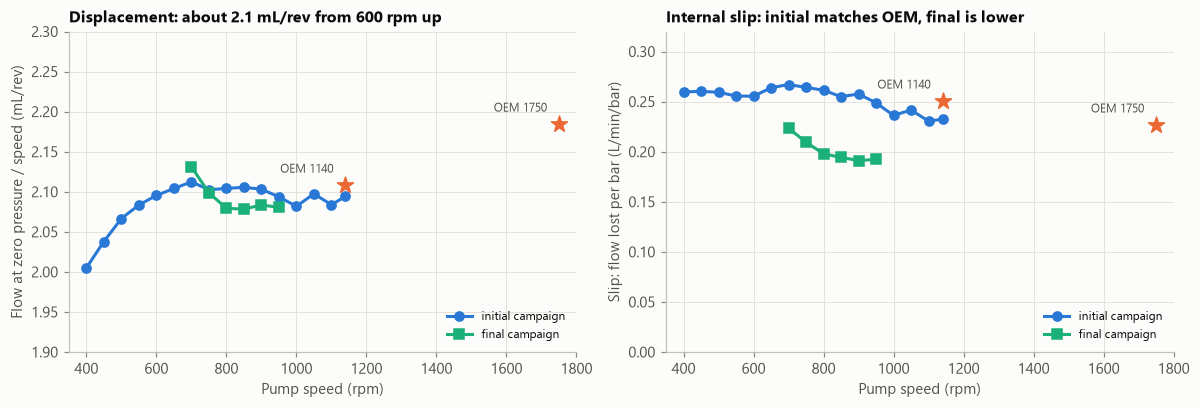

1140 rpm, initial campaign: Q0 = 2.388 L/min, slope = -0.233 L/min/bar
1140 rpm, OEM datasheet:    Q0 = 2.404 L/min, slope = -0.251 L/min/bar
  at 1 bar: test 2.155 vs OEM 2.153 L/min (+0.1 %)
  at 2 bar: test 1.922 vs OEM 1.902 L/min (+1.1 %)
  at 3 bar: test 1.690 vs OEM 1.651 L/min (+2.3 %)


In [6]:
lines = []
for t, g in pt.groupby("test"):
    s = g[g["dP_pump"] < 3.0]
    slope, q0 = np.polyfit(s["dP_pump"], s["Q"], 1)
    lines.append({"test": t, "campaign": g["campaign"].iloc[0], "rpm": g["nominal_rpm"].iloc[0], "Q0": q0,
                  "slope": slope, "displacement_mL_rev": 1000 * q0 / g["nominal_rpm"].iloc[0],
                  "fit sd (L/min)": np.std(s["Q"] - (q0 + slope * s["dP_pump"]))})
lines = pd.DataFrame(lines).sort_values(["campaign", "rpm"])
lines.to_csv(config.TABLE_DIR / "05_pump_lines.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for camp, col, mk in [("initial", pl.SERIES[0], "o"), ("final", pl.SERIES[2], "s")]:
    d = lines[lines["campaign"] == camp]
    axes[0].plot(d["rpm"], d["displacement_mL_rev"], marker=mk, color=col, label=f"{camp} campaign")
    axes[1].plot(d["rpm"], -d["slope"], marker=mk, color=col, label=f"{camp} campaign")
for _, r in oem.iterrows():
    axes[0].scatter(r["rpm"], r["displacement_mL_rev"], marker="*", s=120, color=pl.SERIES[1], zorder=4)
    axes[1].scatter(r["rpm"], -r["slope_Lpm_per_bar"], marker="*", s=120, color=pl.SERIES[1], zorder=4)
    for ax, v in [(axes[0], r["displacement_mL_rev"]), (axes[1], -r["slope_Lpm_per_bar"])]:
        ax.annotate(f"OEM {int(r['rpm'])}", (r["rpm"], v), xytext=(-8, 8), textcoords="offset points",
                    fontsize=8, color=pl.INK_2, ha="right")
axes[0].set_ylabel("Flow at zero pressure / speed (mL/rev)")
axes[0].set_title("Displacement: about 2.1 mL/rev from 600 rpm up")
axes[0].set_ylim(1.9, 2.3)
axes[1].set_ylabel("Slip: flow lost per bar (L/min/bar)")
axes[1].set_title("Internal slip: initial matches OEM, final is lower")
axes[1].set_ylim(0, 0.32)
for ax in axes:
    ax.set_xlabel("Pump speed (rpm)")
    ax.set_xlim(350, 1800)
    ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
pl.save(fig, "05_displacement_slip")
plt.show()

c1140 = lines[(lines["campaign"] == "initial") & (lines["rpm"] == 1140)].iloc[0]
o1140 = oem[oem["rpm"] == 1140].iloc[0]
print(f"1140 rpm, initial campaign: Q0 = {c1140['Q0']:.3f} L/min, slope = {c1140['slope']:.3f} L/min/bar")
print(f"1140 rpm, OEM datasheet:    Q0 = {o1140['Q_at_0bar_Lpm']:.3f} L/min, slope = {o1140['slope_Lpm_per_bar']:.3f} L/min/bar")
for dpv in (1.0, 2.0, 3.0):
    print(f"  at {dpv:.0f} bar: test {c1140['Q0'] + c1140['slope'] * dpv:.3f} vs OEM {pm.oem_flow(1140, dpv):.3f} L/min "
          f"({100 * ((c1140['Q0'] + c1140['slope'] * dpv) / pm.oem_flow(1140, dpv) - 1):+.1f} %)")

* **At 1140 rpm the tested pump matches its datasheet within 0-2.3 %** across the whole pressure
  range below the relief valve (Bardakis, 2019, reported it "slightly better" than the datasheet in
  2019; by 2021 it sits on it). The datasheet is a good model of this pump at the one speed it covers.
* **Displacement is about 2.08-2.13 mL/rev from 600 rpm upwards** in both campaigns, as the
  positive-displacement principle requires, and close to the 2.11 mL/rev implied by the OEM 1140 rpm
  line. It dips to about 2.0 mL/rev at 400 rpm, where the straight-line extrapolation to zero
  pressure is longest and low-speed leakage matters most.
* **Slip** (flow lost per bar) is about **0.25 L/min/bar in 2021**, the same as the datasheet, but only
  **0.19-0.22 in 2023**. Less slip means tighter effective clearances or, more likely, more viscous
  (cooler) water on the test day: slip through a gap scales with 1/viscosity, and water viscosity
  falls by about 2 % per C. The logged "temperature" is a constant 24 C in every file, so this
  cannot be checked. It is the same unmeasured-temperature problem found in the 2014 data
  (notebook 03), seen here between campaigns.

## 5. Building the pump model from the final campaign

Four model families, all mapping (speed, pump pressure) to flow:

| Model | Form | Parameters |
|---|---|---|
| physics (D, k_s) | Q = D n - k_s dP | 2, both physical |
| physics (D, k_s, c) | adds speed-dependent slip, - c n dP | 3 |
| quadratic polynomial | full second-order surface in (dP, n) | 6 |
| 2-D lookup table | binned mean flow, linear interpolation (the MATLAB/Simulink approach) | one per cell |

Training data: the six final-campaign tests below 3.3 bar. Three ways of testing them:
1. **leave one speed out** within the final campaign (can the model fill in a speed it never saw?);
2. the **24 independent verification points** in the module notes (Oberdorfer N999R Gear Pump.pdf,
   Table 1: speeds 777-915 rpm, different valve combinations, measured separately);
3. **other conditions**: the initial campaign (other year, 400-1140 rpm, below the relief bend), the
   OEM 1140 rpm line, and the 2014 rig's healthy point.

In [7]:
train = fin[fin["dP_pump"] < 3.3]
loso = pm.leave_one_speed_out(train)
loso_summary = loso.groupby("model", sort=False)[["rmse_Lpm", "mape_pct", "bias_Lpm", "coverage_pct"]].mean()
rand = pm.random_split_score(train).set_index("model")[["rmse_Lpm", "mape_pct"]]
loso_summary["random-split MAPE % (for contrast)"] = rand["mape_pct"]
loso_summary

,rmse_Lpm,mape_pct,bias_Lpm,coverage_pct,random-split MAPE % (for contrast)
model,,,,,
"physics (D, k_s)",0.016,1.054,2.786e-05,100.000,0.891
"physics (D, k_s, c)",0.011,0.727,1.012e-03,100.000,0.607
quadratic polynomial,0.013,0.867,3.212e-04,100.000,0.589
2-D lookup table,0.009,0.586,-1.886e-03,66.374,0.430


In [8]:
loso.pivot_table(index="held_out_rpm", columns="model", values="mape_pct").round(2)

model,2-D lookup table,"physics (D, k_s)","physics (D, k_s, c)",quadratic polynomial
held_out_rpm,,,,
700,NaN,1.65,1.00,1.56
750,0.65,1.23,0.67,0.74
800,0.43,0.65,0.51,0.56
850,0.43,0.69,0.55,0.50
900,0.83,1.27,0.70,0.70
950,NaN,0.83,0.94,1.13


Within the final campaign all four reach 0.6-1.1 % mean error when a speed is held out; the more
flexible forms are slightly better than the two-parameter physics model here. The lookup table cannot
answer for the two end speeds at all (no extrapolation), and the shuffled split flatters every model.
The differences between model forms are all below about 0.5 percentage points.

Now the independent verification points:

In [9]:
ver = pd.DataFrame([
    (40, 40, 915, 3.059, 1.2824, 1.307), (40, 40, 915, 2.987, 1.2784, 1.321), (55, 55, 915, 2.481, 1.394, 1.424),
    (55, 55, 915, 2.407, 1.3872, 1.439), (80, 80, 915, 1.959, 1.4956, 1.531), (80, 80, 915, 1.925, 1.4996, 1.538),
    (40, 100, 860, 2.175, 1.3152, 1.366), (40, 100, 860, 2.236, 1.314, 1.353), (60, 100, 860, 1.837, 1.3824, 1.435),
    (60, 100, 860, 1.813, 1.3864, 1.439), (80, 100, 860, 1.693, 1.42, 1.464), (80, 100, 860, 1.669, 1.424, 1.469),
    (100, 40, 815, 2.108, 1.2324, 1.28), (100, 40, 815, 2.066, 1.23, 1.289), (100, 55, 815, 1.775, 1.2932, 1.348),
    (100, 55, 815, 1.807, 1.2924, 1.342), (100, 80, 815, 1.486, 1.3516, 1.407), (100, 80, 815, 1.533, 1.352, 1.398),
    (55, 100, 777, 1.605, 1.2384, 1.2999), (55, 100, 777, 1.595, 1.236, 1.301), (100, 100, 777, 1.353, 1.3008, 1.351),
    (100, 100, 777, 1.305, 1.302, 1.36), (100, 100, 890, 1.691, 1.478, 1.53), (100, 100, 890, 1.726, 1.4796, 1.523)],
    columns=["dpv3_pct", "dpv4_pct", "rpm", "dP", "Q_measured", "Q_module_model"])
ver.to_csv(config.TABLE_DIR / "05_verification_points.csv", index=False)
models = {m.name: m.fit(train["rpm"], train["dP_pump"], train["Q"]) for m in pm.default_models()}
vrows = [{"model": "module's MATLAB lookup (as published)", **pm.metrics(ver["Q_measured"], ver["Q_module_model"])}]
for name, m in models.items():
    vrows.append({"model": name, **pm.metrics(ver["Q_measured"], m.predict(ver["rpm"], ver["dP"]))})
vtab = pd.DataFrame(vrows)
vtab

,model,coverage_pct,rmse_Lpm,bias_Lpm,mape_pct,max_abs_pct
0,module's MATLAB lookup (as published),100.000,0.049,0.048,3.582,5.259
1,"physics (D, k_s)",100.000,0.048,0.045,3.413,5.750
2,"physics (D, k_s, c)",100.000,0.048,0.047,3.526,5.260
3,quadratic polynomial,100.000,0.049,0.048,3.576,5.407
4,2-D lookup table,83.333,0.047,0.046,3.480,5.104


**A correction to the published verification table.** Its "Discrepancy [%]" column holds values of
1.27-1.52, which are almost exactly 0.990 x the model's flow in every row, so they are flows, not
percentages (a spreadsheet formula slip). Computed from the table's own measured and model columns,
the published model **over-predicts every one of the 24 points, by 1.9-5.3 % (mean 3.6 %)**, rather
than staying under 1.52 %.

The models fitted here to the same final campaign show the same pattern: a consistent
over-prediction of a few percent on the verification points while matching the training campaign to
within 1 %. A model that is unbiased on its own test day and biased by a fixed few percent on another
day points to **a day-to-day shift in the pump** (or the flow meter), not a modelling error. It is the
same size as the slip change between campaigns and the afternoon shift in the 2014 data, and it is the
main source of error for any of these models in use.

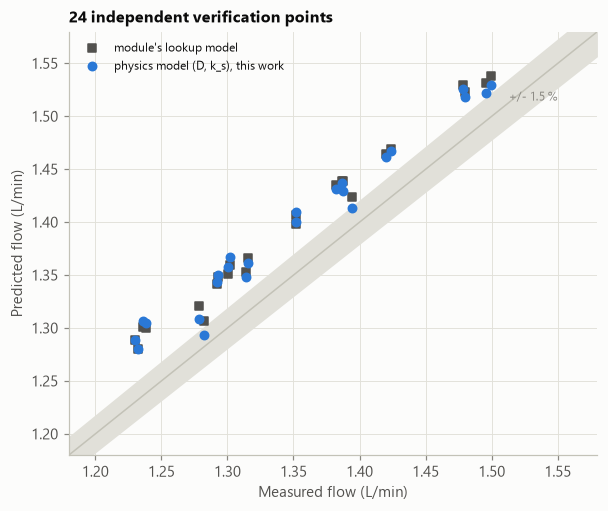

In [10]:
fig, ax = plt.subplots(figsize=(6.2, 5))
lims = [1.18, 1.58]
ax.plot(lims, lims, color=pl.AXIS, lw=1)
ax.fill_between(lims, [l * 0.985 for l in lims], [l * 1.015 for l in lims], color=pl.GRID, lw=0)
ax.text(1.55, 1.55 * 0.985 - 0.012, "+/- 1.5 %", fontsize=8, color=pl.MUTED, ha="right")
phys = models["physics (D, k_s)"]
ax.scatter(ver["Q_measured"], ver["Q_module_model"], marker="s", s=30, color=pl.INK_2, label="module's lookup model")
ax.scatter(ver["Q_measured"], phys.predict(ver["rpm"], ver["dP"]), marker="o", s=30, color=pl.SERIES[0],
           label="physics model (D, k_s), this work")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Measured flow (L/min)")
ax.set_ylabel("Predicted flow (L/min)")
ax.set_title("24 independent verification points")
ax.legend(fontsize=8, loc="upper left")
pl.save(fig, "05_verification")
plt.show()

### Beyond the training conditions

In [11]:
ini_clean = []
for t, g in ini.groupby("test"):
    on = pm.relief_onset(g)["onset_dP_bar"]
    lim = min(3.0, on - 0.1) if np.isfinite(on) else 3.0
    ini_clean.append(g[g["dP_pump"] < lim])
ini_clean = pd.concat(ini_clean)
w = features.load_windows(1.0)
hc = w[w["condition"] == "HC"]
xrows = []
for name, m in models.items():
    for label, sel in [("initial 400-650 rpm (below training speeds)", ini_clean["nominal_rpm"] < 700),
                       ("initial 700-950 rpm (same speeds, other year)", ini_clean["nominal_rpm"].between(700, 950)),
                       ("initial 1000-1140 rpm (above training speeds)", ini_clean["nominal_rpm"] > 950)]:
        d = ini_clean[sel]
        xrows.append({"model": name, "test": label, **pm.metrics(d["Q"], m.predict(d["rpm"], d["dP_pump"]))})
    dp = np.linspace(0, 3.3, 34)
    xrows.append({"model": name, "test": "OEM line 1140 rpm, 0-3.3 bar",
                  **pm.metrics(pm.oem_flow(1140, dp), m.predict(np.full_like(dp, 1140), dp))})
    xrows.append({"model": name, "test": "2014 rig, healthy point (400 rpm)",
                  **pm.metrics(hc["Q"], m.predict(hc["rpm"], hc["dP_pump"]))})
xtab = pd.DataFrame(xrows)
xtab.to_csv(config.TABLE_DIR / "05_model_transfer.csv", index=False)
pd.concat({"mean abs error (%)": xtab.pivot_table(index="test", columns="model", values="mape_pct", sort=False),
           "bias (L/min, + = over-predicts)": xtab.pivot_table(index="test", columns="model", values="bias_Lpm", sort=False)},
          axis=1).round(3)

mean abs error (%)                                                           bias (L/min, + = over-predicts)  \
model                                           physics (D, k_s) physics (D, k_s, c) quadratic polynomial 2-D lookup table                physics (D, k_s)   
test                                                                                                                                                         
initial 400-650 rpm (below training speeds)               19.813              14.489                8.588              NaN                           0.091   
initial 700-950 rpm (same speeds, other year)              8.659               8.457                8.431            9.429                           0.101   
initial 1000-1140 rpm (above training speeds)              5.425               7.201                6.125              NaN                           0.089   
OEM line 1140 rpm, 0-3.3 bar                               3.920               5.216                4.308              NaN                           0.072   
2014 rig, healthy point (400 rpm)                          4.337               2.611                2.241              NaN                           0.031   

                                                                                                         
model                                         physics (D, k_s, c) quadratic polynomial 2-D lookup table  
test                                                                                                     
initial 400-650 rpm (below training speeds)                 0.069                0.046              NaN  
initial 700-950 rpm (same speeds, other year)               0.100                0.099            0.107  
initial 1000-1140 rpm (above training speeds)               0.118                0.100              NaN  
OEM line 1140 rpm, 0-3.3 bar                                0.094                0.041              NaN  
2014 rig, healthy point (400 rpm)                           0.019               -0.016              NaN

Blank = the model cannot answer (the lookup table outside its envelope). Percentage errors are
inflated at the low flows reached by the slow tests, so the bias column is the clearer read.

* **Every model over-predicts the 2021 campaign by about 0.08-0.12 L/min, at every speed**,
  including the speeds it was trained on (700-950 rpm). This is not an extrapolation failure; the pump
  simply delivered less on the 2021 test day at the same speed and pressure.
* That shift is larger than any difference between model forms. Below 700 rpm the polynomial's bias
  happens to be smaller, but no form removes the offset.
* The same pattern appears on the OEM line (about 4-5 %) and on the 2014 rig (2-4 %), and notebook 03
  found the 2014 pump curve much steeper still.

The physics model's parameters show where the shift lives:

In [12]:
camp_par = []
for name, df in [("final 2023 (training)", train), ("initial 2021, below relief", ini_clean)]:
    m = pm.PhysicsPump().fit(df["rpm"], df["dP_pump"], df["Q"])
    camp_par.append({"campaign": name, **{k: round(v, 4) for k, v in m.params.items()}})
camp_par.append({"campaign": "OEM datasheet, 1140 rpm line", "D_mL_rev": round(oem.loc[0, "displacement_mL_rev"], 4),
                 "k_s_Lpm_bar": round(-oem.loc[0, "slope_Lpm_per_bar"], 4)})
pd.DataFrame(camp_par)

,campaign,D_mL_rev,k_s_Lpm_bar
0,final 2023 (training),2.110,0.208
1,"initial 2021, below relief",2.130,0.267
2,"OEM datasheet, 1140 rpm line",2.108,0.251


**Displacement is nearly the same in every source (2.11-2.13 mL/rev); slip is what changes** (0.21 in 2023,
0.27 in 2021, 0.25 on the datasheet). That is the physically expected split: displacement is fixed by
the gear geometry, while slip depends on clearances and on fluid viscosity, i.e. on wear and on
temperature. A pump model for a digital twin should therefore keep D fixed and **treat k_s as a
state to be re-estimated on the asset**; a rising k_s at a known temperature is the wear indicator.

**Choice:** the two-parameter physics model. Inside the test envelope it is within about half a
percentage point of the more flexible forms, its two parameters are physical and are the quantities a
maintenance engineer would track, and its structure is what the twin needs (fixed displacement,
updatable slip). The flexible forms win a little accuracy on the training day but carry six or more
coefficients with no physical meaning, which cannot be updated sensibly when the pump changes.

In [13]:
chosen = models["physics (D, k_s)"]
print({k: round(v, 4) for k, v in chosen.params.items()})
out = {"model": "Q[L/min] = D[mL/rev] * n[rpm] / 1000 - k_s[L/min/bar] * dP[bar]",
       "fitted_on": "final campaign 2023-02-02, 700-950 rpm, dP < 3.3 bar",
       **{k: float(v) for k, v in chosen.params.items()},
       "valid_range": {"rpm": [700, 950], "dP_bar": [1.1, 3.3]},
       "relief_valve_setting_bar": RELIEF}
(config.REPO_ROOT / "results" / "models").mkdir(parents=True, exist_ok=True)
json.dump(out, open(config.REPO_ROOT / "results" / "models" / "pump_model.json", "w"), indent=2)

{'D_mL_rev': np.float64(2.1098), 'k_s_Lpm_bar': np.float64(0.2083)}


## 6. The pump map

The chosen model drawn as a surface over the whole speed range, with the region the tests actually
covered, the relief valve limit and the healthy operating point of the 2014 rig.

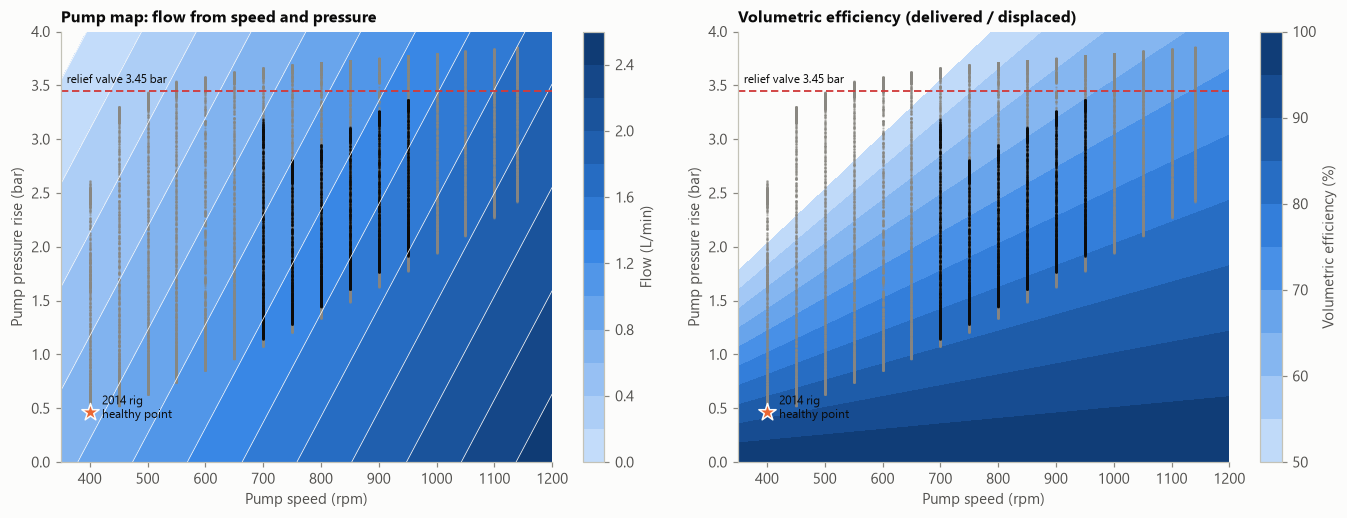

In [14]:
n_grid = np.linspace(350, 1200, 120)
dp_grid = np.linspace(0, 4.0, 120)
N, DP = np.meshgrid(n_grid, dp_grid)
Qs = chosen.predict(N.ravel(), DP.ravel()).reshape(N.shape)
eff = chosen.volumetric_efficiency(N.ravel(), DP.ravel()).reshape(N.shape)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax = axes[0]
cs = ax.contourf(N, DP, Qs, levels=np.arange(0, 2.61, 0.2), cmap=pl.BLUE_RAMP)
ax.contour(N, DP, Qs, levels=np.arange(0, 2.61, 0.2), colors=pl.SURFACE, linewidths=0.5)
fig.colorbar(cs, ax=ax, label="Flow (L/min)")
ax.set_title("Pump map: flow from speed and pressure")
ax = axes[1]
cs2 = ax.contourf(N, DP, 100 * eff, levels=np.arange(50, 101, 5), cmap=pl.BLUE_RAMP)
fig.colorbar(cs2, ax=ax, label="Volumetric efficiency (%)")
ax.set_title("Volumetric efficiency (delivered / displaced)")
for ax in axes:
    ax.axhline(RELIEF, color=pl.STATUS["critical"], lw=1.2, ls=(0, (4, 2)))
    ax.text(360, RELIEF + 0.05, "relief valve 3.45 bar", fontsize=8, color=pl.INK, va="bottom")
    for camp, mk in [("initial", "."), ("final", ".")]:
        d = pt[pt["campaign"] == camp]
        ax.scatter(d["rpm"], d["dP_pump"], s=0.5, color=pl.INK if camp == "final" else pl.MUTED, alpha=0.4)
    ax.scatter([400], [hc["dP_pump"].mean()], marker="*", s=140, color=pl.SERIES[1], edgecolor=pl.SURFACE, zorder=4)
    ax.annotate("2014 rig\nhealthy point", (400, hc["dP_pump"].mean()), xytext=(8, -4), textcoords="offset points",
                fontsize=8, color=pl.INK)
    ax.set_xlabel("Pump speed (rpm)")
    ax.set_ylabel("Pump pressure rise (bar)")
    ax.grid(False)
fig.tight_layout()
pl.save(fig, "05_pump_map")
plt.show()

Dark dots: final-campaign test points (the training envelope); grey dots: initial campaign. The map
is trustworthy inside the dark region, reasonable along the straight-line physics elsewhere below the
relief valve, and meaningless above 3.45 bar, where the relief valve, not the gears, sets the flow.

Volumetric efficiency falls quickly at low speed: at 400 rpm and 0.5 bar the pump delivers only about
85-90 % of what it displaces, so the 2014 rig at 400 rpm runs in the region where slip (and therefore
temperature and wear) matters most.

## 7. Power and overall efficiency (context from the datasheet)

The datasheet's shaft-power lines allow a rough overall efficiency at 1140 rpm: hydraulic power
(flow x pressure) over shaft power.

In [15]:
dp = np.array([0.5, 1.0, 2.0, 3.0])
q = chosen.predict(np.full_like(dp, 1140), dp)
hyd = q / 60000 * dp * 1e5
shaft = pm.oem_power_w(1140, dp)
pd.DataFrame({"pump pressure (bar)": dp, "flow (L/min)": q, "hydraulic power (W)": hyd,
              "OEM shaft power (W)": shaft, "overall efficiency (%)": 100 * hyd / shaft}).round(2)

,pump pressure (bar),flow (L/min),hydraulic power (W),OEM shaft power (W),overall efficiency (%)
0,0.5,2.30,1.92,7.10,27.00
1,1.0,2.20,3.66,14.20,25.78
2,2.0,1.99,6.63,28.41,23.33
3,3.0,1.78,8.90,42.61,20.89


A small bronze gear pump at this duty is inefficient (about 20-27 % overall), so most of the
drive power becomes heat in the water. That is the mechanism behind the temperature drift seen
through the day in the 2014 data, and another reason a twin of this system needs fluid temperature.

## Summary for Task 4

* The tested N999R matches its datasheet at 1140 rpm within 0-2.3 %; displacement is about
  2.1 mL/rev across the speed range (2.0 at 400 rpm).
* The initial campaign's flow collapse above 600 rpm is the **built-in relief valve** (50 psig =
  3.45 bar) opening; the initial tests all closed the valves to 9.9 % open and pushed the pump past it,
  while the final campaign stopped at 25-35 % open to stay below it.
* A two-parameter physics model (displacement 2.11 mL/rev, slip 0.21 L/min/bar) fitted to the final
  campaign predicts held-out speeds to about 1 %; more flexible forms are slightly better on the
  training day, and the lookup table cannot extrapolate at all.
* Shifts between test days dominate the real-world error: about +3.5 % on the 24 independent
  verification points (for every model, including the module's own, whose published error figures are
  mis-computed) and about +0.1 L/min against the 2021 campaign. They live in the slip coefficient, not
  the displacement, so the twin should keep D fixed and re-estimate k_s on the asset.